# Retention curves: shape and floor: where is the floor?

**Week 4, Thursday, SECTION 2, the second of five concept notebooks.** The gym and its thirty
members are invented, the same branch as notebook 01, which built its cohort table: January's
joiners kept 80, 60, 50, 50 and 50 percent at ages one to five. This notebook reads each row as
a curve.

**Who needs the answer.** The gym's owner, who staffs the floor for the regulars. The level a
batch stops falling at says how many joiners became regulars, and a level read too early staffs
for members who are about to leave.

**The questions on the way.**

1. How fast does a batch fall?
2. Where does it stop falling?
3. When can a floor be called?
4. Which batch is strongest, fairly?

In [1]:
# Load the same register (invented), print it, and rebuild notebook 01's cohort table in one cell.
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = []
def check(name, ok):
    RESULTS.append(bool(ok)); print(("PASS  " if ok else "FAIL  ") + name)

MONTHS = ["jan", "feb", "mar", "apr", "may", "jun"]
roster = pd.read_csv("../data/C2_W04_D04_toy_gym_roster_STUDENT.csv", dtype={m: "Int64" for m in MONTHS})
print("One branch's register, January to June 2026 (invented), in full:")
print(roster.astype(object).where(roster.notna(), "").to_string(index=False))
PLACE = {"jan": 0, "feb": 1, "mar": 2, "apr": 3, "may": 4, "jun": 5}
long = roster.melt(id_vars=["member_id", "joined"], var_name="month", value_name="visited").dropna()
long["visited"] = long["visited"].astype(int)
long["age"] = long["month"].map(PLACE) - long["joined"].map(PLACE)
tri = long[long["age"] >= 1].pivot_table(index="joined", columns="age", values="visited",
                                         aggfunc="mean", sort=False)
check("the rebuilt table is notebook 01's: 8, 6, 5, 5, 5 of 10 in January's row",
      [round(10 * v) for v in tri.loc["jan"]] == [8, 6, 5, 5, 5])
(100 * tri).round(0)

One branch's register, January to June 2026 (invented), in full:
member_id joined jan feb mar apr may jun
      G01    jan   1   1   1   1   1   1
      G02    jan   1   1   0   0   0   0
      G03    jan   1   1   1   1   1   1
      G04    jan   1   0   0   0   0   0
      G05    jan   1   1   1   0   0   0
      G06    jan   1   1   1   1   1   1
      G07    jan   1   1   1   1   1   1
      G08    jan   1   1   0   0   0   0
      G09    jan   1   0   0   0   0   0
      G10    jan   1   1   1   1   1   1
      G11    feb       1   1   1   1   1
      G12    feb       1   0   0   0   0
      G13    feb       1   1   1   0   0
      G14    feb       1   1   1   1   1
      G15    feb       1   1   0   0   0
      G16    feb       1   0   0   0   0
      G17    feb       1   1   1   1   1
      G18    feb       1   1   1   0   0
      G19    feb       1   0   0   0   0
      G20    feb       1   1   0   0   0
      G21    mar           1   1   1   1
      G22    mar           1   0 

age,1,2,3,4,5
joined,,,,,
jan,80.0,60.0,50.0,50.0,50.0
feb,70.0,50.0,30.0,30.0,NaN
mar,60.0,40.0,30.0,NaN,NaN


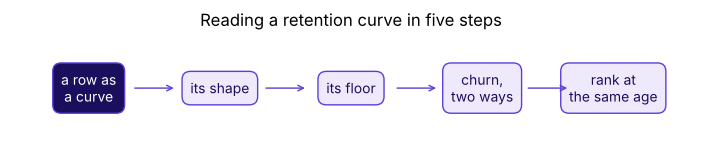

In [2]:
# The map: the chapter's steps in order; this notebook starts on the lit one and walks them all.
steps = ["a row as\na curve", "its shape", "its floor", "churn,\ntwo ways", "rank at\nthe same age"]
fig, ax = plt.subplots(figsize=(8.8, 1.4))
for i, s in enumerate(steps):
    ax.text(i, 0, s, ha="center", va="center", fontsize=10, color="white" if i == 0 else "#1A0F5C",
            bbox=dict(boxstyle="round,pad=0.6", fc="#1A0F5C" if i == 0 else "#EEEAFB", ec="#5B3FD6"))
for i in range(1, len(steps)):
    ax.annotate("", xy=(i - 0.33, 0), xytext=(i - 0.67, 0), arrowprops=dict(arrowstyle="->", color="#5B3FD6"))
ax.set_xlim(-0.6, len(steps) - 0.4); ax.set_ylim(-0.7, 0.7); ax.axis("off")
ax.set_title("Reading a retention curve in five steps"); plt.show()

## How fast does a batch fall, and where does it stop?

A **retention curve** is one cohort's row of the table, drawn by age. **Predict before you
run.** January's ten joiners read 80, 60 and then 50 percent at ages one to three. What do they
read at age five?

- a) About 25 percent, the fall carrying on
- b) 50 percent
- c) Under 10 percent
- d) Back up to 80 percent

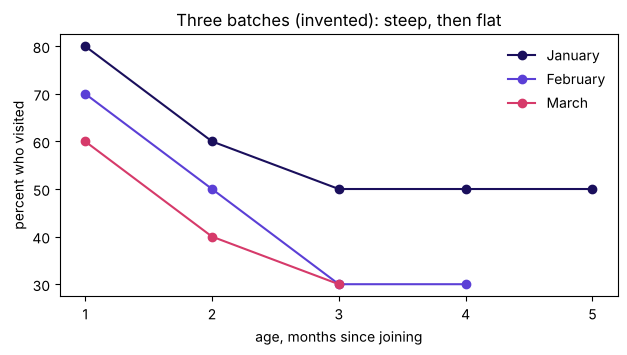

January: [80, 60, 50, 50, 50]


In [3]:
# The three batches as curves, one line each, age on the bottom.
names = {"jan": "January", "feb": "February", "mar": "March"}
colours = {"jan": "#1A0F5C", "feb": "#5B3FD6", "mar": "#D63A6A"}
fig, ax = plt.subplots(figsize=(7.2, 3.4))
for c, row in tri.iterrows():
    row = row.dropna()
    ax.plot(row.index, 100 * row.values, marker="o", color=colours[c], label=names[c])
ax.set_xticks(range(1, 6)); ax.set_xlabel("age, months since joining"); ax.set_ylabel("percent who visited")
ax.legend(frameon=False); ax.set_title("Three batches (invented): steep, then flat"); plt.show()
print("January:", [round(100 * v) for v in tri.loc["jan"]])

**What happened.** The answer is b: 80, 60, 50, 50, 50. A curve's **shape** is how fast it falls
in its first ages: January fell 20 points from age one to age two, then 10, then none. A point is the gap
between two percentages, so 80 to 60 is a fall of 20 points. Its **floor** is the level where it
stops falling: January's is 50, the five of ten who made visiting a habit, and February's is 30.
March reads 60, 40, 30 and is still falling, so its floor is not known yet.

## What share of a batch has stopped, counted two ways?

**Churn** is the share lost. Counted so far, it is 100 less the retention: January has lost 20
percent of its joiners by age one, 40 by age two and 50 by age three. Counted month to month, it
divides those who stopped by those still visiting the month before: at age two, 2 of the 8 who
visited at age one stopped, 25 percent. By hand, January's month-to-month churn reads 20, 25,
16.7, 0 and 0. In this branch no member came back after stopping, which is what lets both
counts work and the month-to-month count divide by last month's visitors. Where members do come
back, a team first picks when a member counts as gone, for example 60 days with no visit, and
labels that a choice.

age                                1     2     3     4     5
still visiting                  80.0  60.0  50.0  50.0  50.0
churned so far                  20.0  40.0  50.0  50.0  50.0
stopped since the month before  20.0  25.0  16.7   0.0   0.0
PASS  month-to-month churn matches the hand count: 20, 25, 16.7, 0, 0
PASS  churn so far plus retention is 100 at every age


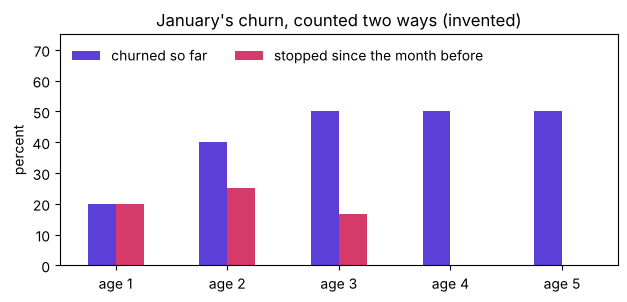

In [4]:
# Churn two ways for January, against the hand count, and drawn side by side.
jan = tri.loc["jan"]
so_far = (100 * (1 - jan)).round(1)
visiting = 10 * jan                                           # members still visiting, of 10
before = pd.concat([pd.Series({0: 10.0}), visiting.iloc[:-1]]).values
month_to_month = (100 * (before - visiting.values) / before).round(1)
by_hand = [20, 25, 16.7, 0, 0]
print(pd.DataFrame({"still visiting": (100 * jan).round(0), "churned so far": so_far,
                    "stopped since the month before": month_to_month}).T)
check("month-to-month churn matches the hand count: 20, 25, 16.7, 0, 0", list(month_to_month) == by_hand)
check("churn so far plus retention is 100 at every age", ((so_far + (100 * jan).round(1)) == 100).all())
ax = pd.DataFrame({"churned so far": so_far.values, "stopped since the month before": month_to_month},
                  index=[f"age {a}" for a in jan.index]).plot.bar(figsize=(7.2, 3.0), rot=0,
                                                                 color=["#5B3FD6", "#D63A6A"])
ax.set_ylim(0, 75); ax.legend(frameon=False, ncol=2, loc="upper left")
ax.set_ylabel("percent"); ax.set_title("January's churn, counted two ways (invented)"); plt.show()

## When can a floor be called?

**The plausible wrong answer.** After February's age two, 5 of 10, the owner staffed for a floor
of five regulars. Ages three and four read 3 of 10, so the plan counted two regulars too many.
**Why it is wrong.** One age after a big drop looks settled and is not. **The rule we use, this
programme's own:** call a floor only when two ages in a row read within a point of each other;
until then the curve is still falling. A batch of ten moves in steps of ten points, so on the
gym that means two equal ages; on a large cohort exact equality almost never happens, which is
why the rule allows a point. The next cell writes the rule as a function, `floor_of`, and tests
it on January's row and on February's row as the owner saw it after age two.

January: [0.8, 0.6, 0.5, 0.5, 0.5] floor: 0.5
February as the owner saw it after age two: [0.7, 0.5] floor: None
PASS  January's floor is 0.5, reached at age three and called at age four
PASS  February cut at age two has no floor yet


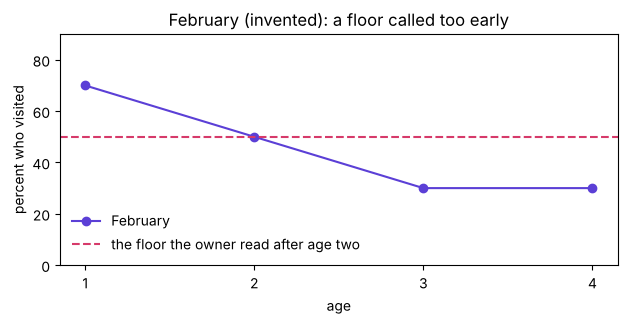

In [5]:
# The two-ages rule as a function, tested on January and on February cut at age two.
def floor_of(row, within=0.01):                          # row: shares at ages 1, 2, 3, ...
    pairs = zip(row, row[1:])
    near = (b for a, b in pairs if abs(a - b) <= within)
    return next(near, None)                              # None: still falling

jan_row, feb_row = list(tri.loc["jan"].dropna()), list(tri.loc["feb"].dropna())
print("January:", jan_row, "floor:", floor_of(jan_row))
print("February as the owner saw it after age two:", feb_row[:2], "floor:", floor_of(feb_row[:2]))
check("January's floor is 0.5, reached at age three and called at age four",
      floor_of(jan_row) == 0.5 and jan_row.index(0.5) + 1 == 3)
check("February cut at age two has no floor yet", floor_of(feb_row[:2]) is None)
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(range(1, len(feb_row) + 1), [100 * v for v in feb_row], marker="o", color="#5B3FD6", label="February")
ax.axhline(100 * feb_row[1], ls="--", color="#D63A6A", label="the floor the owner read after age two")
ax.set_xticks(range(1, len(feb_row) + 1)); ax.set_ylim(0, 90); ax.legend(frameon=False, loc="lower left")
ax.set_xlabel("age"); ax.set_ylabel("percent who visited")
ax.set_title("February (invented): a floor called too early"); plt.show()

## Which batch is strongest, fairly?

The owner's April reading ranked March first, 6 of 10 against 5 and 5. Age two is the oldest
age that all three batches have lived. **Predict before you run.** Ranked at age two, in which
order do the batches fall?

- a) March, then February, then January, as April's row ranked them
- b) January, then February, then March
- c) All three tie
- d) February, then January, then March

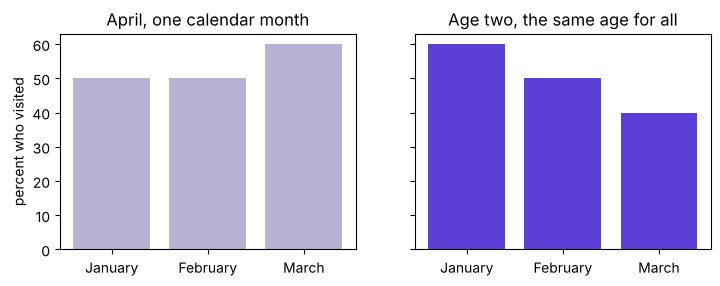

age two: {'January': 60, 'February': 50, 'March': 40}
PASS  at age two the order is January, February, March: 60, 50, 40


In [6]:
# The ranking at the same age, beside the ranking by one calendar month.
april = roster.groupby("joined", sort=False)["apr"].sum().astype(int)
age_two = tri[2]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.4, 2.8), sharey=True)
a1.bar(list(names.values()), 10 * april.values, color="#B8B2D6"); a1.set_title("April, one calendar month")
a2.bar(list(names.values()), 100 * age_two.values, color="#5B3FD6"); a2.set_title("Age two, the same age for all")
a1.set_ylabel("percent who visited"); plt.show()
print("age two:", {names[c]: round(100 * v) for c, v in age_two.items()})
check("at age two the order is January, February, March: 60, 50, 40",
      [round(100 * v) for v in age_two] == [60, 50, 40])

**What happened.** The answer is b: 60, 50 and 40 percent at age two. Ranked at the same age,
January is strongest and March weakest, the reverse of April's calendar row. March reads 60, 40,
30: it has lived only three ages and is still falling, so its floor is open. A batch that has not
lived enough ages to show its floor is the plain-words version of censoring, the name used by
the IITGN faculty session W4-3 (tentative) this afternoon.

## Your turn: which floors can be called today?

**Your turn.** In the empty cell, apply `floor_of` to February's full row and to March's row, and
say which floor can be called and from which age.

```python
floor_of(list(tri.loc["feb"].dropna())), floor_of(list(tri.loc["mar"].dropna()))
```

**Check your cell against this one.** It prints both floors, then counts every check this
notebook has run.

In [7]:
# February's floor and March's open end; then every check in this notebook counted.
feb_floor, mar_floor = floor_of(list(tri.loc["feb"].dropna())), floor_of(list(tri.loc["mar"].dropna()))
print("February's floor:", feb_floor, "   March's floor:", mar_floor)
check("February's floor is 0.3, read where ages three and four agree; March has none yet",
      feb_floor == 0.3 and mar_floor is None)
check("March is still falling at its last age", tri.loc["mar"].dropna().diff().iloc[-1] < 0)
print(f"{sum(RESULTS)} of {len(RESULTS)} checks pass")

February's floor: 0.3    March's floor: None
PASS  February's floor is 0.3, read where ages three and four agree; March has none yet
PASS  March is still falling at its last age
8 of 8 checks pass


## What does an analyst read off every retention curve?

1. A retention curve is one cohort's row of the table, drawn by age.
2. The shape says how fast a cohort leaves; the floor says how many stay where members who stop
   never return, and otherwise the share active in a typical month.
3. Cohorts are ranked at the same age, never by the latest calendar month.
4. A young cohort has no floor yet, since it has not lived the ages that would show one.

**In the interview.** [F] "How would you use cohort analysis to find a retention issue?" Read
each cohort's shape and floor, rank cohorts at the same age, and look for the cohort whose curve
starts lower or never flattens.

**What comes next.** Notebook 03 puts one number over every cohort and asks what it is made of.
Notebook 06 draws Gold's eight curves on 53,089 members.